In [116]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas_datareader as data

plt.style.use('fivethirtyeight')
%matplotlib inline

In [117]:
import yfinance as yf
import datetime as dt

stock = "POWERGRID.NS"
start = dt.datetime(2000,1,1)
end = dt.datetime(2026,11,1)

df =yf.download(stock,start,end)

/tmp/ipykernel_925/3691478571.py:8: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed


In [118]:
df.head()

Price,Close,High,Low,Open,Volume
Ticker,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS
Date,,,,,
2007-10-05,30.399626,33.089057,25.126529,27.136048,855215656
2007-10-08,28.843380,31.427045,28.662069,31.427045,126671715
2007-10-09,30.807579,31.079543,27.302254,28.858496,116725709
2007-10-10,31.094650,31.729236,30.822686,31.608361,67931378
2007-10-11,34.569752,36.261978,30.822682,36.261978,106320954


In [119]:
df.shape

(4702, 5)

In [120]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4702 entries, 2007-10-05 to 2026-10-30
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   (Close, POWERGRID.NS)   4702 non-null   float64
 1   (High, POWERGRID.NS)    4702 non-null   float64
 2   (Low, POWERGRID.NS)     4702 non-null   float64
 3   (Open, POWERGRID.NS)    4702 non-null   float64
 4   (Volume, POWERGRID.NS)  4702 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 220.4 KB


In [121]:
df.isnull().sum()

,,0
Price,Ticker,
Close,POWERGRID.NS,0
High,POWERGRID.NS,0
Low,POWERGRID.NS,0
Open,POWERGRID.NS,0
Volume,POWERGRID.NS,0


In [122]:
df.describe()

Price,Close,High,Low,Open,Volume
Ticker,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS
count,4702.000000,4702.000000,4702.000000,4702.000000,4.702000e+03
mean,96.154014,97.338533,94.988233,96.205323,1.193886e+07
std,84.842604,85.756010,83.913898,84.869726,1.963596e+07
min,17.748899,18.972961,15.912807,18.881156,0.000000e+00
25%,34.947126,35.536082,34.442232,35.053240,5.098311e+06
50%,66.214157,67.024964,65.244393,66.049813,8.690062e+06
75%,124.373095,125.920599,122.946627,124.403557,1.381477e+07
max,339.300415,340.043190,331.640740,338.000569,8.552157e+08


In [123]:
df = df.reset_index()

In [124]:
df.shape

(4702, 6)

In [125]:
df.head()

Price,Date,Close,High,Low,Open,Volume
Ticker,,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS
0,2007-10-05,30.399626,33.089057,25.126529,27.136048,855215656
1,2007-10-08,28.843380,31.427045,28.662069,31.427045,126671715
2,2007-10-09,30.807579,31.079543,27.302254,28.858496,116725709
3,2007-10-10,31.094650,31.729236,30.822686,31.608361,67931378
4,2007-10-11,34.569752,36.261978,30.822682,36.261978,106320954


In [126]:
df.columns

MultiIndex([(  'Date',             ''),
            ( 'Close', 'POWERGRID.NS'),
            (  'High', 'POWERGRID.NS'),
            (   'Low', 'POWERGRID.NS'),
            (  'Open', 'POWERGRID.NS'),
            ('Volume', 'POWERGRID.NS')],
           names=['Price', 'Ticker'])

In [127]:
df.to_csv("powergrid.csv")

In [128]:
data01 = pd.read_csv("powergrid.csv")

In [129]:
data01.head()

,Price,Date,Close,High,Low,Open,Volume
0,Ticker,NaN,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS
1,0,2007-10-05,30.399625778198242,33.08905650493982,25.126529225787998,27.136048001001512,855215656
2,1,2007-10-08,28.843379974365234,31.427045467503728,28.662069324235876,31.427045467503728,126671715
3,2,2007-10-09,30.807579040527344,31.07954304795203,27.302253781994803,28.85849613984495,116725709
4,3,2007-10-10,31.094650268554688,31.729235637075533,30.822686281651713,31.608361160099435,67931378


In [130]:
# Candlestick plot
import plotly.graph_objects as go
fig = go.Figure(data=[go.Candlestick(x=data01['Date'],
                open=data01['Open'],
                high=data01['High'],
                low=data01['Low'],
                close=data01['Close'])])
fig.update_layout(xaxis_rangeslider_visible=False)
fig.show()

In [131]:
df = df.drop(['Date'], axis=1)

/tmp/ipykernel_925/3771822584.py:1: PerformanceWarning:

dropping on a non-lexsorted multi-index without a level parameter may impact performance.



In [132]:
df.head()

Price,Close,High,Low,Open,Volume
Ticker,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS
0,30.399626,33.089057,25.126529,27.136048,855215656
1,28.843380,31.427045,28.662069,31.427045,126671715
2,30.807579,31.079543,27.302254,28.858496,116725709
3,31.094650,31.729236,30.822686,31.608361,67931378
4,34.569752,36.261978,30.822682,36.261978,106320954


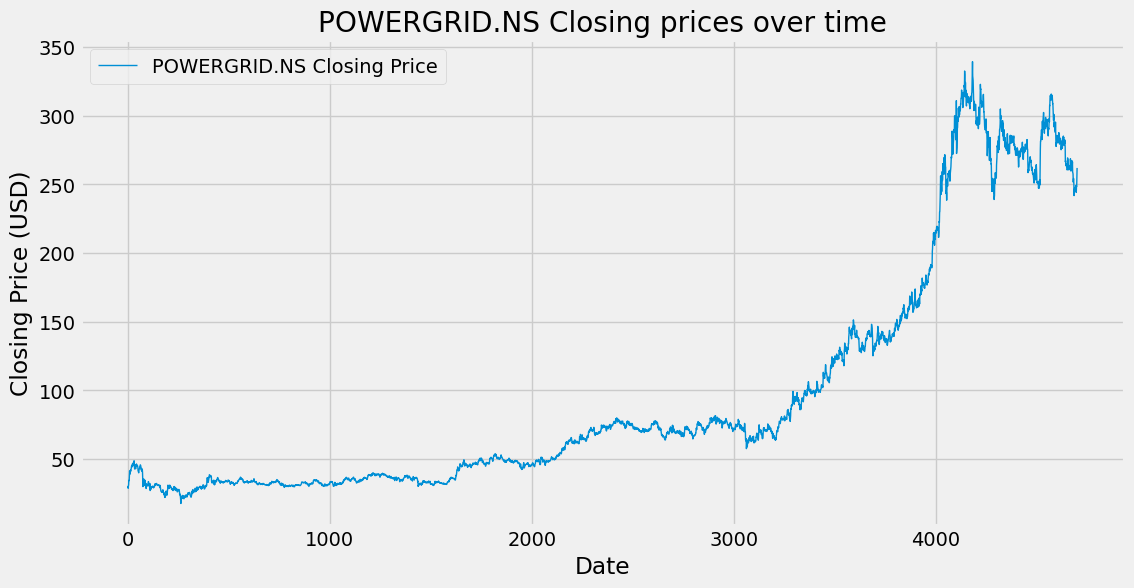

In [133]:
plt.figure(figsize=(12,6))
plt.plot(df['Close'],label=f'{stock} Closing Price', linewidth=1)
plt.title(f'{stock} Closing prices over time')
plt.xlabel('Date')
plt.ylabel('Closing Price (USD)')
plt.legend()
plt.show()

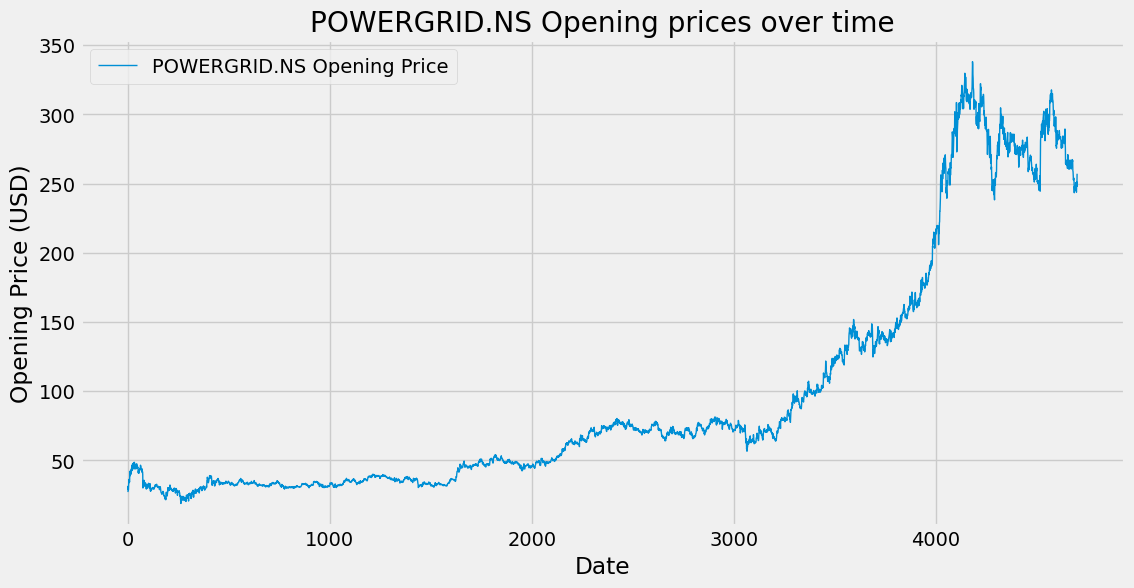

In [134]:
plt.figure(figsize=(12,6))
plt.plot(df['Open'],label=f'{stock} Opening Price', linewidth=1)
plt.title(f'{stock} Opening prices over time')
plt.xlabel('Date')
plt.ylabel('Opening Price (USD)')
plt.legend()
plt.show()

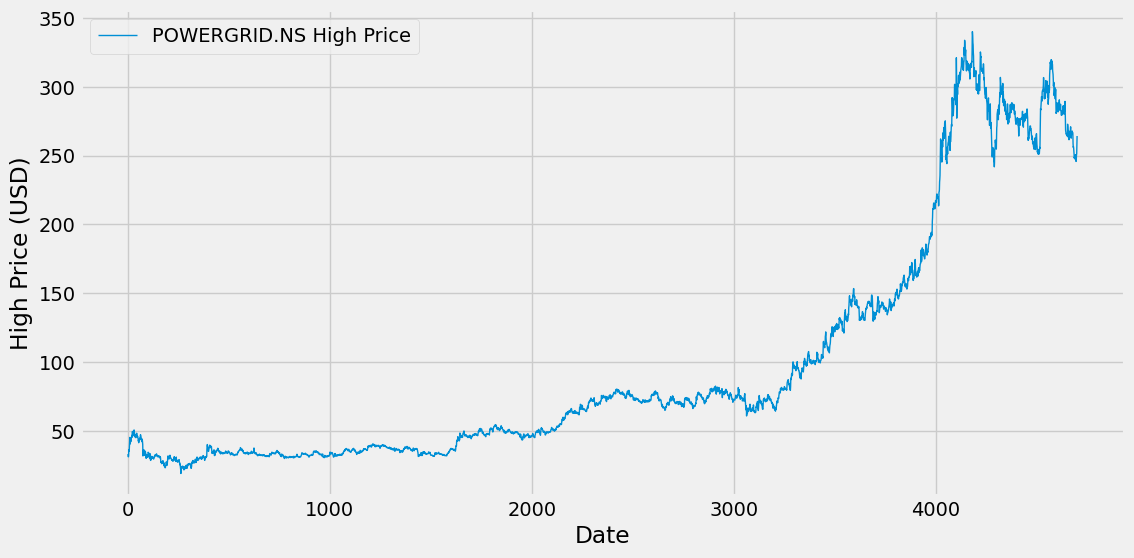

In [135]:
plt.figure(figsize=(12,6))
plt.plot(df['High'],label=f'{stock} High Price', linewidth=1)
plt.xlabel('Date')
plt.ylabel('High Price (USD)')
plt.legend()
plt.show()

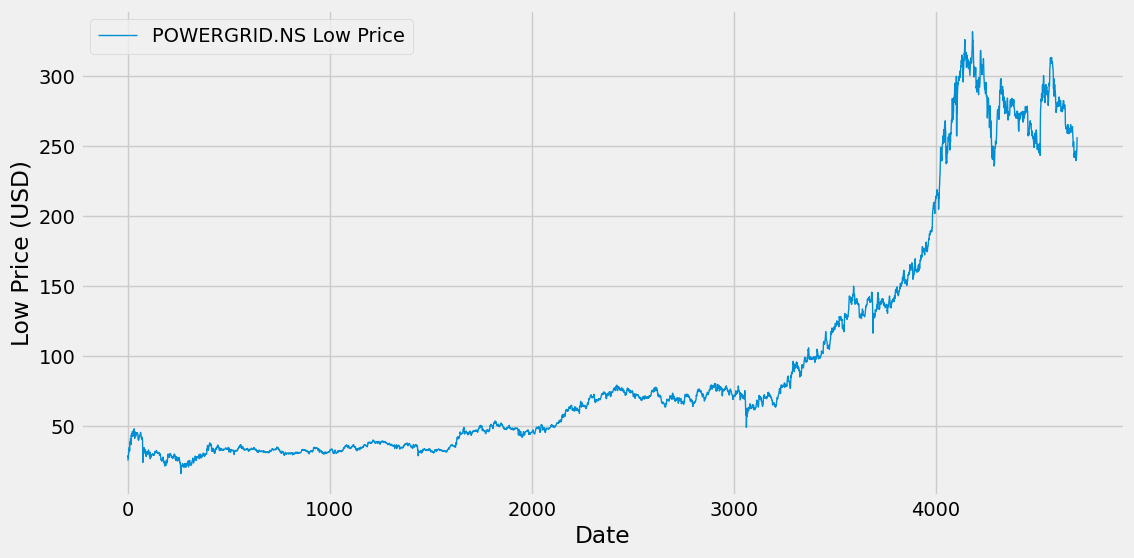

In [136]:
plt.figure(figsize=(12,6))
plt.plot(df['Low'],label=f'{stock} Low Price', linewidth=1)
plt.xlabel('Date')
plt.ylabel('Low Price (USD)')
plt.legend()
plt.show()

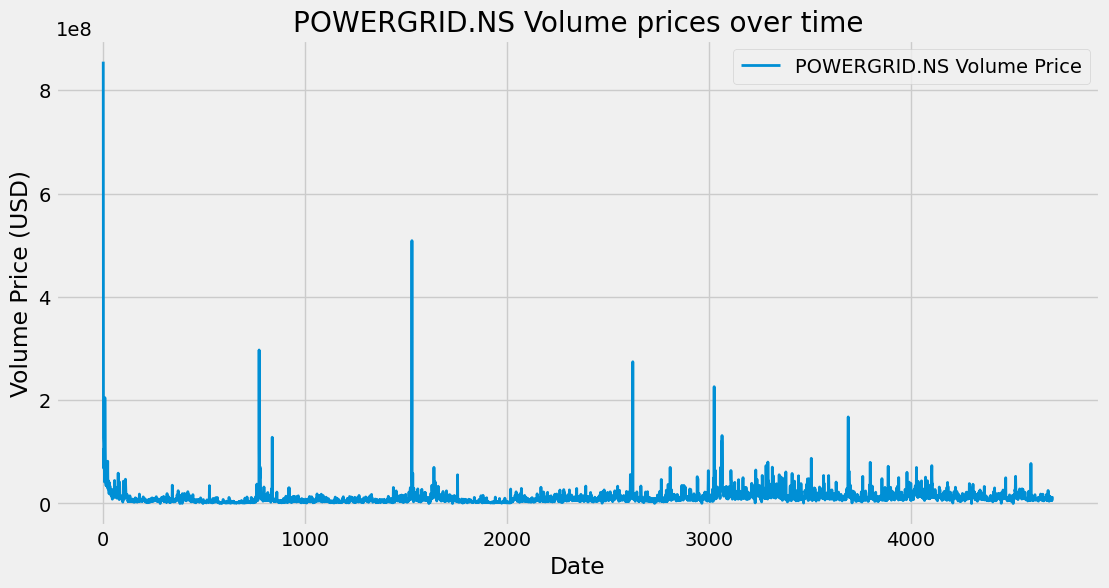

In [137]:
plt.figure(figsize=(12,6))
plt.plot(df['Volume'],label=f'{stock} Volume Price', linewidth=2)
plt.title(f'{stock} Volume prices over time')
plt.xlabel('Date')
plt.ylabel('Volume Price (USD)')
plt.legend()
plt.show()

In [138]:
# Technique of Moving Average
temp_data =[10,20,30,40,50,60,70]
print(sum(temp_data[0:5])/5)
df01 = pd.DataFrame(temp_data)
df01

30.0


,0
0,10
1,20
2,30
3,40
4,50
5,60
6,70


In [139]:
df01.rolling(5).mean()

,0
0,NaN
1,NaN
2,NaN
3,NaN
4,30.0
5,40.0
6,50.0


In [140]:
ma100 = df.Close.rolling(100).mean()
ma100

Ticker,POWERGRID.NS
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
...,...
4697,269.075195
4698,268.759093
4699,268.443958
4700,268.203504


In [141]:
ma200 = df.Close.rolling(200).mean()
ma200

Ticker,POWERGRID.NS
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
...,...
4697,278.247428
4698,278.173541
4699,278.094519
4700,278.073085


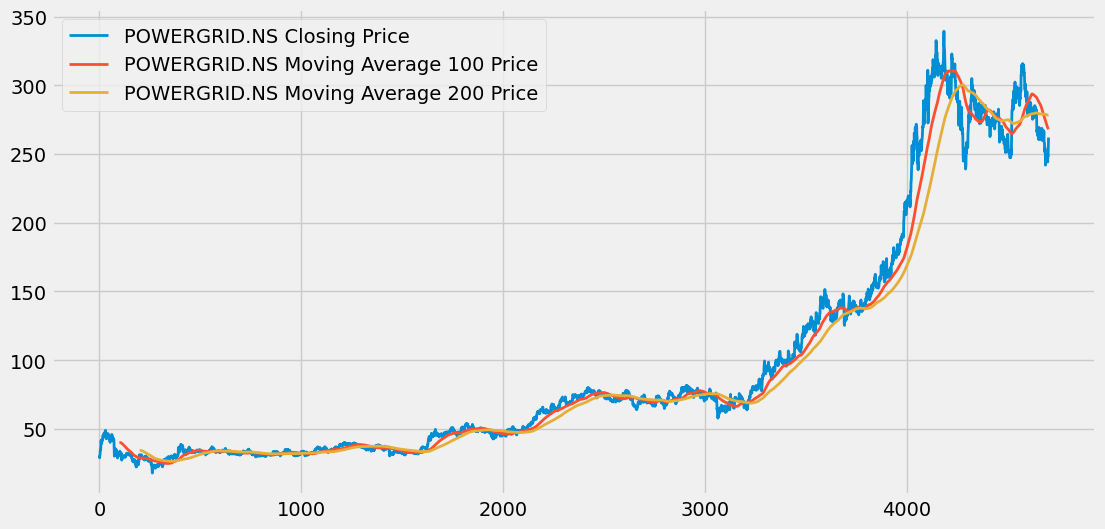

In [142]:
plt.figure(figsize=(12,6))
plt.plot(df["Close"],label=f'{stock} Closing Price', linewidth=2)
plt.plot(ma100,label=f'{stock} Moving Average 100 Price', linewidth=2)
plt.plot(ma200,label=f'{stock} Moving Average 200 Price', linewidth=2)
plt.legend()
plt.show()

In [143]:
ema100 = df.Close.ewm(span=100,adjust=False).mean()

In [144]:
ema200 = df.Close.ewm(span=200,adjust=False).mean()

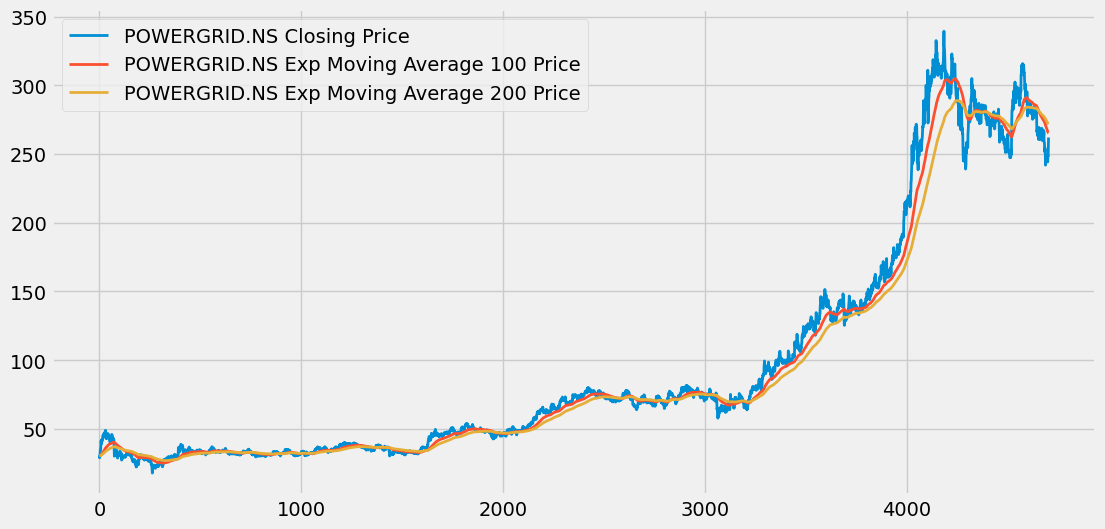

In [145]:
plt.figure(figsize=(12,6))
plt.plot(df["Close"],label=f'{stock} Closing Price', linewidth=2)
plt.plot(ema100,label=f'{stock} Exp Moving Average 100 Price', linewidth=2)
plt.plot(ema200,label=f'{stock} Exp Moving Average 200 Price', linewidth=2)
plt.legend()
plt.show()

Training and Testing

In [146]:
data_training = pd.DataFrame(df['Close'][0:int(len(df) *0.70)])
data_testing = pd.DataFrame(df['Close'][int(len(df) *0.70):int(len(df))])

print("Training shape:", data_training.shape)
print("Testing shape:", data_testing.shape)

Training shape: (3291, 1)
Testing shape: (1411, 1)


In [147]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))

In [148]:
data_training_array =scaler.fit_transform(data_training)
data_training_array

array([[0.17563241],
       [0.15402676],
       [0.1812961 ],
       ...,
       [0.98075693],
       [1.        ],
       [0.99358557]], shape=(3291, 1))

In [149]:
x_train = []
y_train = []

for i in range(100,data_training_array.shape[0]):
  x_train.append(data_training_array[i-100:i])
  y_train.append(data_training_array[i,0])

x_train, y_train = np.array(x_train), np.array(y_train)

In [150]:
x_train.shape

(3191, 100, 1)

#LSTM
### Next 30 days stock price

In [151]:
# Model Building
from keras.layers import Dense, Dropout, LSTM
from keras.models import Sequential

LSTM Input -> 3D Array (batch_size, time_steps, seq_len)

LSTM 2D or 3D

2D -> (batch_sizem units)

3D -> (batch_size, time_steps, units)

In [152]:
model = Sequential()
model.add(LSTM(units=50, activation='relu', return_sequences=True, input_shape=(x_train.shape[1],1)))
model.add(Dropout(0.2))

model.add(LSTM(units=60, activation='relu', return_sequences=True))
model.add(Dropout(0.3))

model.add(LSTM(units=80, activation='relu', return_sequences=True))
model.add(Dropout(0.4))

model.add(LSTM(units=120, activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(units=1))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



In [153]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_20 (LSTM)                  │ (None, 100, 50)        │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 100, 50)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_21 (LSTM)                  │ (None, 100, 60)        │        26,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 100, 60)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_22 (LSTM)                  │ (None, 100, 80)        │        45,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 100, 80)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_23 (LSTM)                  │ (None, 120)            │        96,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           121 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 178,761 (698.29 KB)

 Trainable params: 178,761 (698.29 KB)

 Non-trainable params: 0 (0.00 B)

In [154]:
model.compile(optimizer='adam', loss='mean_squared_error')
model.fit(x_train, y_train, epochs=50)

Epoch 1/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 33s 265ms/step - loss: 0.0294
Epoch 2/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 41s 265ms/step - loss: 0.0074
Epoch 3/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 41s 265ms/step - loss: 0.0067
Epoch 4/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 26s 263ms/step - loss: 0.0058
Epoch 5/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 41s 267ms/step - loss: 0.0058
Epoch 6/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 27s 266ms/step - loss: 0.0050
Epoch 7/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 41s 262ms/step - loss: 0.0046
Epoch 8/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 27s 270ms/step - loss: 0.0046
Epoch 9/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 26s 261ms/step - loss: 0.0044
Epoch 10/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 26s 264ms/step - loss: 0.0041
Epoch 11/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 41s 260ms/step - loss: 0.0037
Epoch 12/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 26s 261ms/step - loss: 0.0036
Epoch 13/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 26s 260ms/step - loss: 0.0036
Epoch 14/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 41s 267ms/step - loss: 0.0031
Epoch 15/50
100

In [155]:
past_100_days=data_training.tail(100)

In [156]:
final_df = pd.concat([past_100_days, data_testing], ignore_index=True)

In [157]:
final_df.head()

Ticker,POWERGRID.NS
0,69.091919
1,67.086304
2,65.223930
3,65.796967
4,68.825874


In [158]:
input_data = scaler.fit_transform(final_df)
input_data

array([[0.01938491],
       [0.01210632],
       [0.00534757],
       ...,
       [0.67051925],
       [0.70137108],
       [0.71930817]], shape=(1511, 1))

In [159]:
x_test = []
y_test = []

for i in range(100,input_data.shape[0]):
  x_test.append(input_data[i-100:i])
  y_test.append(input_data[i,0])

x_test, y_test = np.array(x_test), np.array(y_test)

In [160]:
x_test.shape

(1411, 100, 1)

In [161]:
y_predicted = model.predict(x_test)

45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 80ms/step


In [162]:
y_predicted.shape

(1411, 1)

In [163]:
scaler.scale_

array([0.00362911])

In [172]:
# Reset variables from input_data first to prevent scaling multiple times
x_test = []
y_test = []

for i in range(100, input_data.shape[0]):
  x_test.append(input_data[i-100:i])
  y_test.append(input_data[i,0])

x_test, y_test = np.array(x_test), np.array(y_test)

# Generate predictions and apply scaling
y_predicted = model.predict(x_test)
scaler_factor = 1 / scaler.scale_[0]
y_predicted = y_predicted * scaler_factor
y_test = y_test * scaler_factor

45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step


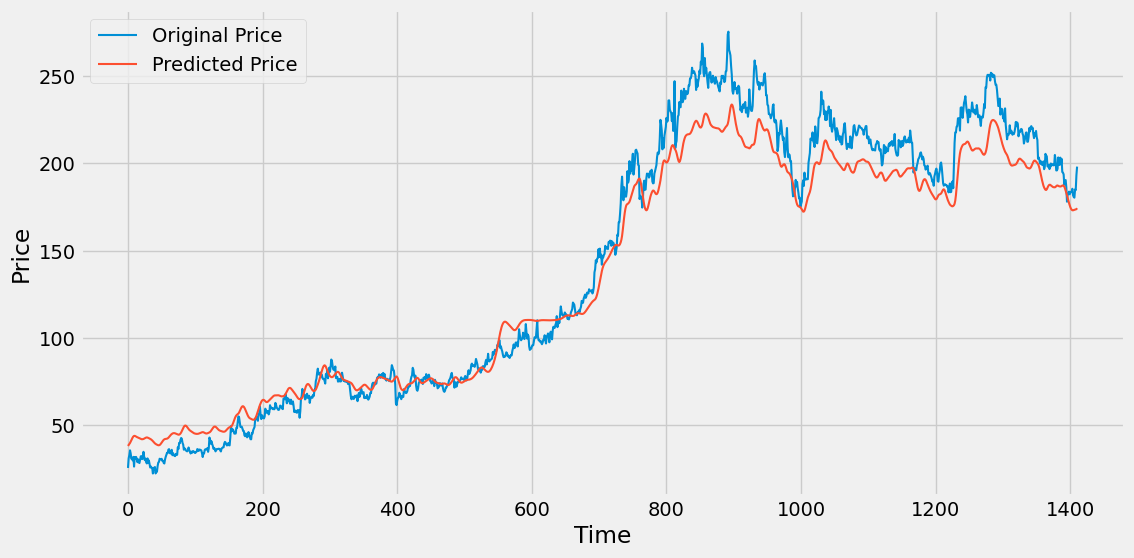

In [173]:
plt.figure(figsize=(12,6))
plt.plot(y_test, label='Original Price', linewidth=1.5)
plt.plot(y_predicted, label='Predicted Price', linewidth=1.5)
plt.xlabel('Time')
plt.ylabel('Price')
plt.grid(visible=True)
plt.legend()
plt.show()

In [174]:
model.save('stock_dl_model.keras')